In [35]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten

In [36]:
(X_train,Y_train),(X_test,Y_test) = keras.datasets.mnist.load_data()

In [37]:
X_test.shape # 60000 images of 28x28 pixels

(10000, 28, 28)

In [38]:
X_train.shape # 10000 images of 28x28 pixels

(60000, 28, 28)

In [39]:
Y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [40]:
Y_test

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8)

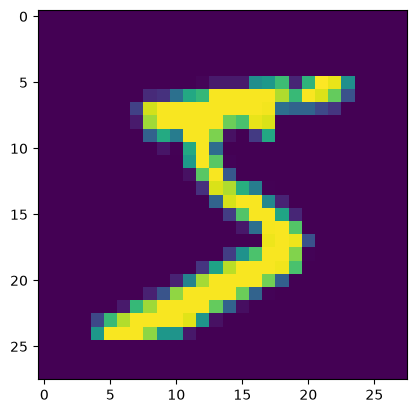

In [41]:
import matplotlib.pyplot as plt
plt.imshow(X_train[0])

In [42]:
# Standardization of arrays by diving by 255 to bring the values between 0 and 1 -- Beacause 255 is the Highest number in the pixel values of the image. So, we divide by 255 to bring the values between 0 and 1.
X_train = X_train / 255
X_test = X_test / 255

In [43]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [44]:
model = Sequential()
model.add(Flatten(input_shape=(28,28))) #3 Input Layer
model.add(Dense(128,activation='relu')) # 1st Hidden Layer
model.add(Dense(64,activation='relu')) # 2nd Hidden Layer
model.add(Dense(10,activation='softmax')) # Output Layer

In [45]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [47]:
history = model.fit(X_train,Y_train,validation_data=(X_test,Y_test),epochs=10) 
# Validation Split When We give testig as per percentage
# Validation Data When We give testing data is Fixed

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9294 - loss: 0.2411 - val_accuracy: 0.9539 - val_loss: 0.1478
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9680 - loss: 0.1036 - val_accuracy: 0.9684 - val_loss: 0.1073
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9771 - loss: 0.0731 - val_accuracy: 0.9749 - val_loss: 0.0850
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9822 - loss: 0.0541 - val_accuracy: 0.9763 - val_loss: 0.0831
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9860 - loss: 0.0443 - val_accuracy: 0.9786 - val_loss: 0.0732
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9896 - loss: 0.0329 - val_accuracy: 0.9806 - val_loss: 0.0706
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9902 - loss: 0.0293 - val_accuracy: 0.9746 - val_loss: 0.0985
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9918 - loss: 0.0242 - 

In [ ]:
y_pred = model.predict

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [49]:
print("Predicted Value:",y_pred[0])

Predicted Value: [1.43869801e-12 5.07032567e-08 1.81314130e-10 1.32324125e-08
 8.55730790e-15 5.74083055e-12 6.17846594e-18 9.99999881e-01
 7.17780761e-13 1.04363416e-08]


In [50]:
import numpy as np
y_pred = np.argmax(y_pred,axis=1)
print("Predicted Value:",y_pred)

Predicted Value: [7 2 1 ... 4 5 6]


In [51]:
from sklearn.metrics import accuracy_score,classification_report
accuracy_score(Y_test,y_pred)

0.9791

In [ ]:
print("Predicted Value:",y_pred[0])

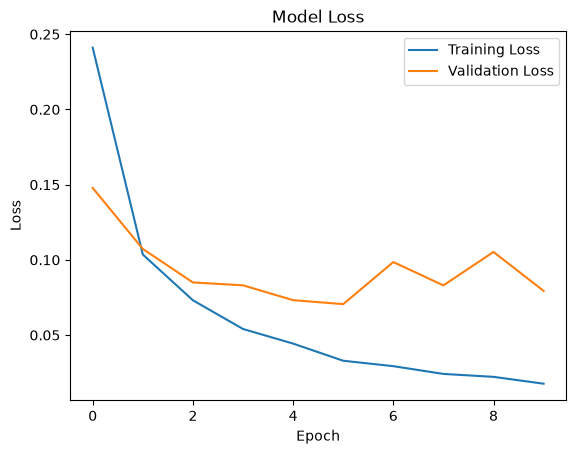

In [52]:
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

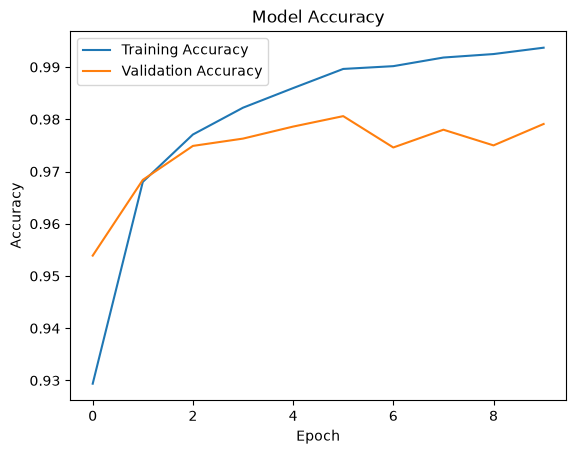

In [53]:
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()